# 4. Reinforcement learning: a tiny 2D grid

An agent starts at the top-left of a 3 × 3 grid and learns to reach the bottom-right goal. It can move up, down, left or right. Coordinates are (row, column), starting at zero. Each move receives a small penalty, while reaching the goal earns +1. There are no labelled correct actions: feedback is a reward. This is a simulation, **not** safe robot control.

**Setup:** Follow [README.md](README.md) to create a virtual environment,
install all packages and choose the `Python (AGR9027 ML)` kernel. Run all cells
in order. All observations here are artificial; ML is optional for Assessment 2.

In [7]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(4)
grid_size = 3
start, goal = (0, 0), (2, 2)
actions = [("up", (-1, 0)), ("down", (1, 0)),
           ("left", (0, -1)), ("right", (0, 1))]
n_actions = len(actions)
q = np.zeros((grid_size, grid_size, n_actions))

def step(state, action):
    """Move within the grid and return next state, reward and goal status."""
    row_change, col_change = actions[action][1]
    next_state = (int(np.clip(state[0] + row_change, 0, grid_size - 1)),
                  int(np.clip(state[1] + col_change, 0, grid_size - 1)))
    done = next_state == goal
    reward = 1.0 if done else -0.02
    return next_state, reward, done

def plot_episode(history, title):
    """Show a grid for the start and each recorded action and reward."""
    positions = [start] + [transition[2] for transition in history]
    columns = 4
    rows = (len(positions) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(12, 3 * rows), squeeze=False)
    for index, ax in enumerate(axes.flat):
        if index >= len(positions):
            ax.axis("off")
            continue
        row, col = positions[index]
        ax.scatter(goal[1], goal[0], marker="s", s=700, color="lightgreen", label="Goal")
        ax.scatter(col, row, s=120, color="royalblue", label="Agent", zorder=3)
        ax.set_xticks(range(grid_size))
        ax.set_yticks(range(grid_size))
        ax.set_xlim(-0.5, grid_size - 0.5)
        ax.set_ylim(grid_size - 0.5, -0.5)
        ax.set_aspect("equal")
        ax.grid(alpha=0.4)
        ax.set_xlabel("Column")
        ax.set_ylabel("Row")
        if index == 0:
            ax.set_title("Step 0: start")
        else:
            previous, action, current, reward = history[index - 1]
            stayed = " (boundary)" if previous == current else ""
            ax.set_title(f"Step {index}: {actions[action][0]}{stayed}\nreward {reward:+.2f}")
    fig.suptitle(title + " — blue: agent, green: goal")
    fig.tight_layout()
    plt.show()

## Train

An **episode** starts at (0, 0) and ends at the goal or after 10 steps. This short limit helps illustrate both successes and timeouts. Attempts to move beyond the grid leave the agent in place. At each step, the agent sometimes explores a random action (probability `epsilon`) and otherwise chooses the action with the highest Q-value. The Q update combines the immediate reward with the best expected future reward. `alpha` controls how much each update changes the value, and `gamma` controls the importance of future rewards. The plot shows how many steps each episode took; 10 steps may mean a timeout rather than reaching the goal.

Training episodes reaching goal: 494 / 500
Q-values for start (up, down, left, right): [0.583 0.668 0.587 0.675]


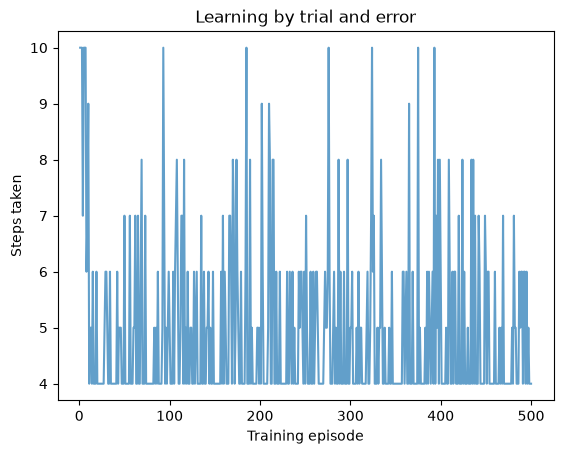

In [8]:
alpha, gamma, epsilon = 0.2, 0.9, 0.2
successes = 0
episode_steps = []
example_episodes = {}  # First recorded success and timeout, if available.
for episode in range(500):
    state = start
    episode_transitions = []
    for step_number in range(1, 11):
        action = int(rng.integers(n_actions)) if rng.random() < epsilon else int(np.argmax(q[state]))
        next_state, reward, done = step(state, action)
        episode_transitions.append((state, action, next_state, reward))
        future = 0.0 if done else np.max(q[next_state])
        q[state][action] += alpha * (reward + gamma * future - q[state][action])
        state = next_state
        if done:
            successes += 1
            break
    episode_steps.append(step_number)
    if done not in example_episodes:
        example_episodes[done] = (episode + 1, episode_transitions)
print("Training episodes reaching goal:", successes, "/ 500")
print("Q-values for start (up, down, left, right):", np.round(q[start], 3))
plt.plot(range(1, len(episode_steps) + 1), episode_steps, alpha=0.7)
plt.xlabel("Training episode")
plt.ylabel("Steps taken")
plt.title("Learning by trial and error")
plt.show()

## Compare two training episodes

These are the first successful and timed-out episodes actually recorded during training, not separate demonstrations. Each panel is one step, read left to right and then down: the blue circle is the agent and the green square is the goal. The title shows the action and reward that led to the panel. Step 0 is the start. A boundary move leaves the agent in the same position. In a timeout, the episode stops at the step limit without reaching the goal. If changed settings produce only one outcome, the missing example is reported rather than invented.

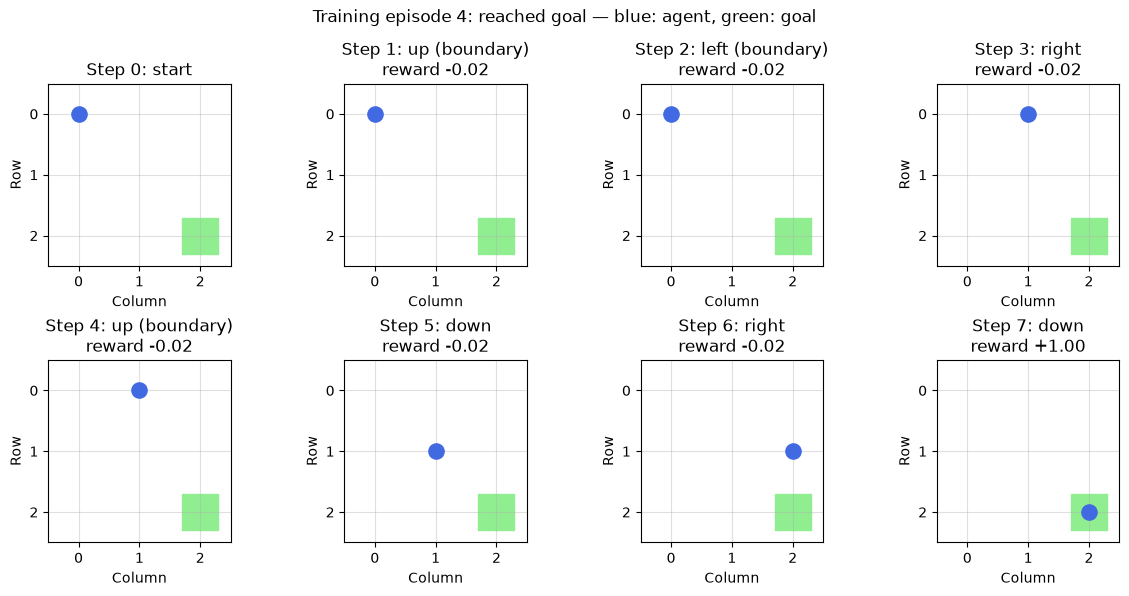

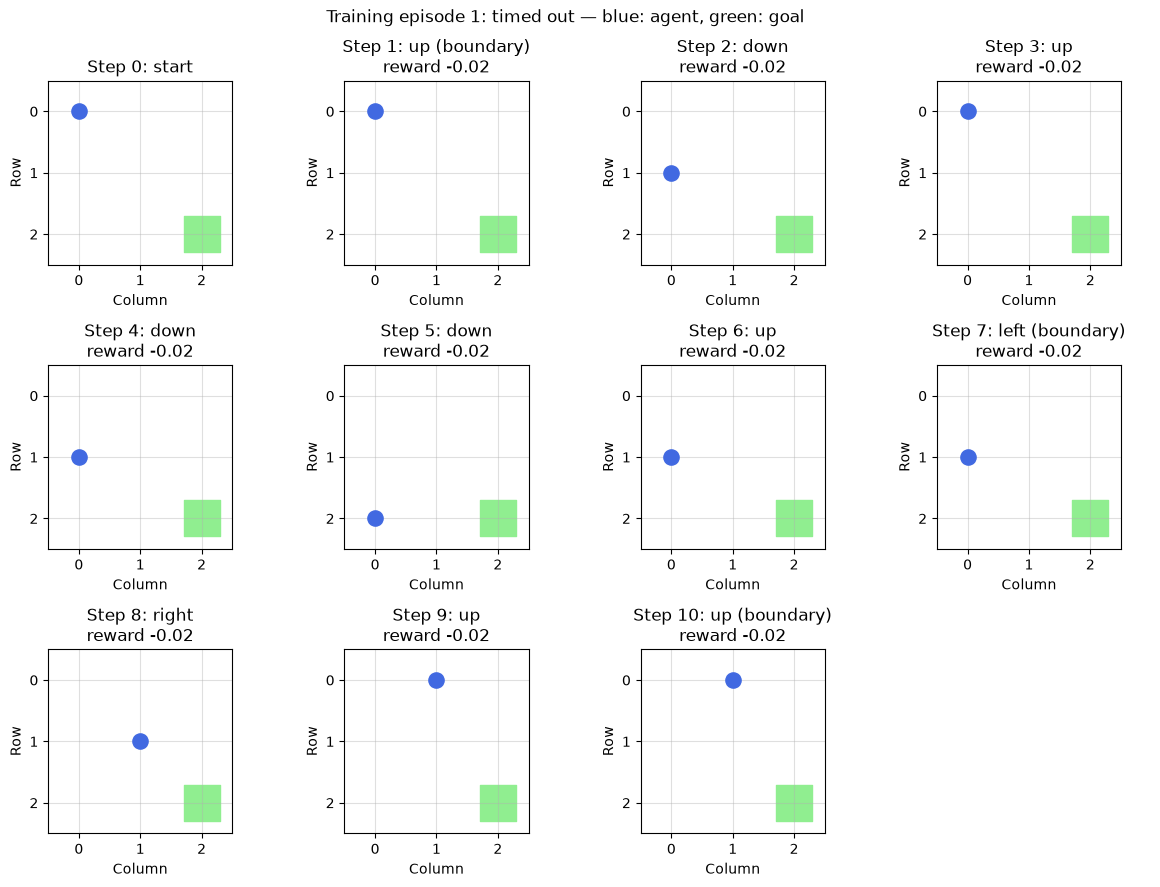

In [9]:
for reached in (True, False):
    if reached not in example_episodes:
        print(f"No {'successful' if reached else 'timed-out'} training episode was recorded.")
        continue
    episode_number, history = example_episodes[reached]
    outcome = "reached goal" if reached else "timed out"
    plot_episode(history, f"Training episode {episode_number}: {outcome}")


## Use the learned policy without exploration

The agent now selects the highest Q-value at each position, without random exploration. The panels display the **post-training** route, not the exploratory steps taken during training. As above, blue is the agent and green is the goal.

In [ ]:
state = start
route = [state]
transitions = []
done = False
for _ in range(30):
    action = int(np.argmax(q[state]))
    previous_state = state
    state, reward, done = step(previous_state, action)
    transitions.append((previous_state, action, state, reward))
    route.append(state)
    if done:
        break
print("Greedy route:", route, "reached goal:", done)
for index, (previous, action, current, reward) in enumerate(transitions, start=1):
    direction = actions[action][0]
    print(f"Step {index}: {previous} -> {current}, {direction}, reward {reward:+.2f}")

plot_episode(transitions, "Learned route: " + ("reached goal" if done else "timed out"))

**Try:** Change `epsilon = 0.2` to `0.5` in the training cell to explore more often, or change the `-0.02` step reward in the `step` function. Run all cells again to reset the Q-table and compare the training plot and route. Physical robots need safety limits, obstacle handling and extensive testing; this toy environment does not provide them.